# U²-Net Face Parsing: Baseline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/u2net
!ls

/content/drive/MyDrive/u2net
dataset.py   loss.py	 model.py  run_baseline.ipynb
evaluate.py  metrics.py  old	   train.py


In [ ]:
import os, shutil

ARCHIVE = "/content/drive/MyDrive/u2net/LaPa.zip"
LAPA_ID = "1XOBoRGSraP50_pS1YPB8_i8Wmw_5L-NG"

def detect(path):
    with open(path, "rb") as f:
        head = f.read(512)
    if head[:2] == b"PK": return "zip"
    if head[:2] == b"\x1f\x8b": return "gzip"
    if head[257:262] == b"ustar": return "tar"
    if head[:4] == b"Rar!": return "rar"
    if head[:6] == b"7z\xbc\xaf\x27\x1c": return "7z"
    if head[:5].lower() in (b"<!doc", b"<html"): return "html"
    return "unknown"

if not os.path.exists("/content/LaPa"):
    if not os.path.exists(ARCHIVE):
        !pip install -q gdown
        !gdown {LAPA_ID} -O {ARCHIVE}

    kind = detect(ARCHIVE)
    print("Archive size (GB):", round(os.path.getsize(ARCHIVE) / 1e9, 2), "| detected type:", kind)

    os.makedirs("/content/lapa_tmp", exist_ok=True)
    if kind == "zip":
        !unzip -q -o {ARCHIVE} -d /content/lapa_tmp
    elif kind in ("gzip", "tar"):
        !tar -xf {ARCHIVE} -C /content/lapa_tmp
    elif kind == "7z":
        !apt-get -qq install -y p7zip-full > /dev/null
        !7z x -y -o/content/lapa_tmp {ARCHIVE} > /dev/null
    elif kind == "rar":
        !apt-get -qq install -y unrar > /dev/null
        !unrar x -inul {ARCHIVE} /content/lapa_tmp/
    else:
        os.remove(ARCHIVE)
        raise RuntimeError(f"Downloaded file is not a usable archive (type: {kind}). Removed it; run this cell again.")

    for root, dirs, _ in os.walk("/content/lapa_tmp"):
        if {"train", "val", "test"} <= set(dirs):
            shutil.move(root, "/content/LaPa")
            break

for split in ["train", "val", "test"]:
    for kind_ in ["images", "labels"]:
        p = f"/content/LaPa/{split}/{kind_}"
        print(p, len(os.listdir(p)) if os.path.exists(p) else "MISSING")

Archive size (GB): 2.37 | detected type: gzip
/content/LaPa/train/images 18168
/content/LaPa/train/labels 18168
/content/LaPa/val/images 2000
/content/LaPa/val/labels 2000
/content/LaPa/test/images 2000
/content/LaPa/test/labels 2000


In [ ]:
import torch
print(torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

True
Tesla T4


In [ ]:
# Train (resumes from checkpoints/last.pth if it exists)
!python train.py

Using: cuda
Training images: 9000
Validation images: 2000
No checkpoint found, starting from scratch
Epoch 1/20: 100% 563/563 [02:56<00:00,  3.20it/s, loss=1.79]
Epoch 1 | train loss 2.5105 | val mean F1 0.7008 | val mIoU 0.5541 | pixel acc 0.9306
  new best model saved (val mean F1 0.7008)
Epoch 2/20: 100% 563/563 [02:56<00:00,  3.18it/s, loss=1.38]
Epoch 2 | train loss 1.4405 | val mean F1 0.7897 | val mIoU 0.6585 | pixel acc 0.9468
  new best model saved (val mean F1 0.7897)
Epoch 3/20: 100% 563/563 [02:58<00:00,  3.15it/s, loss=1.09]
Epoch 3 | train loss 1.2005 | val mean F1 0.7984 | val mIoU 0.6721 | pixel acc 0.9510
  new best model saved (val mean F1 0.7984)
Epoch 4/20: 100% 563/563 [03:02<00:00,  3.09it/s, loss=1.05]
Epoch 4 | train loss 1.0618 | val mean F1 0.8416 | val mIoU 0.7311 | pixel acc 0.9597
  new best model saved (val mean F1 0.8416)
Epoch 5/20: 100% 563/563 [02:57<00:00,  3.16it/s, loss=1.05]
Epoch 5 | train loss 0.9998 | val mean F1 0.8437 | val mIoU 0.7348 | pixel

In [ ]:
# Final evaluation
!python evaluate.py


Test images: 2000
Mean F1 (excl. background): 0.8938
Mean IoU (excl. background): 0.8108
Pixel accuracy: 0.9764

class               F1     IoU
background      0.9881  0.9765
skin            0.9675  0.9370
left_brow       0.8675  0.7659
right_brow      0.8766  0.7804
left_eye        0.8838  0.7919
right_eye       0.8814  0.7880
nose            0.9537  0.9115
upper_lip       0.8407  0.7251
inner_mouth     0.8575  0.7506
lower_lip       0.8635  0.7597
hair            0.9460  0.8975

Saved checkpoints/test_results.json


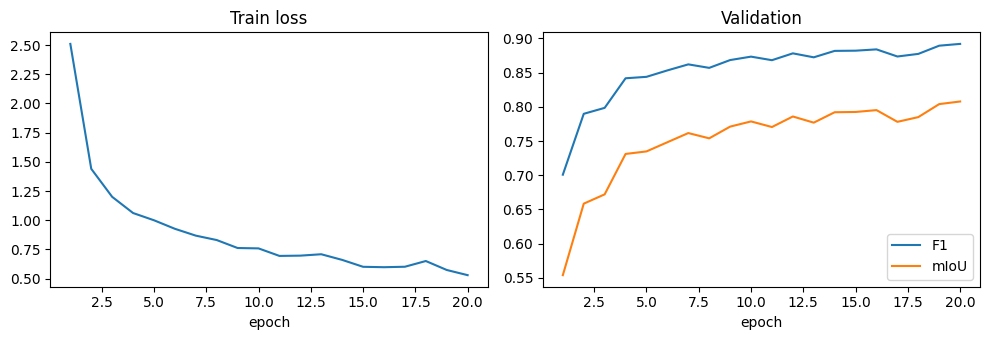

In [ ]:
# Training curves from the log
import pandas as pd
import matplotlib.pyplot as plt

log = pd.read_csv('checkpoints/log.csv')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(log['epoch'], log['train_loss']); ax[0].set_title('Train loss'); ax[0].set_xlabel('epoch')
ax[1].plot(log['epoch'], log['val_mean_f1'], label='F1')
ax[1].plot(log['epoch'], log['val_mean_iou'], label='mIoU')
ax[1].set_title('Validation'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig('checkpoints/curves.png', dpi=150)
plt.show()

In [ ]:
!cp -r checkpoints checkpoints_9k